<a href="https://colab.research.google.com/github/Nihat0311/Computer-Vision/blob/main/Object_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import random
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split

import torchvision
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.transforms import v2

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm.auto import tqdm

from PIL import Image
import xml.etree.ElementTree as ET

In [ ]:
!curl -L -o fruit-detection.zip\
  https://www.kaggle.com/api/v1/datasets/download/andrewmvd/fruit-detection

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 51.3M  100 51.3M    0     0  54.3M      0 --:--:-- --:--:-- --:--:-- 80.2M


In [ ]:
!unzip -q /content/fruit-detection.zip -d fruit-detection

In [ ]:
img_path='/content/fruit-detection/images/fruit0.png'
xml_path='/content/fruit-detection/annotations/fruit0.xml'

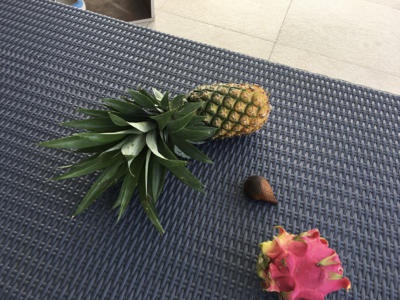

In [ ]:
image=Image.open(img_path).convert('RGB')
image

In [ ]:
root=ET.parse(xml_path).getroot()
root

<Element 'annotation' at 0x7ad44cfaff60>

In [ ]:
obj=root.find('object')
obj

<Element 'object' at 0x7ad44ce2c220>

In [ ]:
label=obj.find('name').text

In [ ]:
label

'pineapple'

In [ ]:
bbox=obj.find('bndbox')
bbox

<Element 'bndbox' at 0x7ad44ce2c400>

In [ ]:
xmin=int(bbox.find('xmin').text)
ymin=int(bbox.find('ymin').text)
xmax=int(bbox.find('xmax').text)
ymax=int(bbox.find('ymax').text)

In [ ]:
xmin,ymin,xmax,ymax

(38, 82, 271, 227)

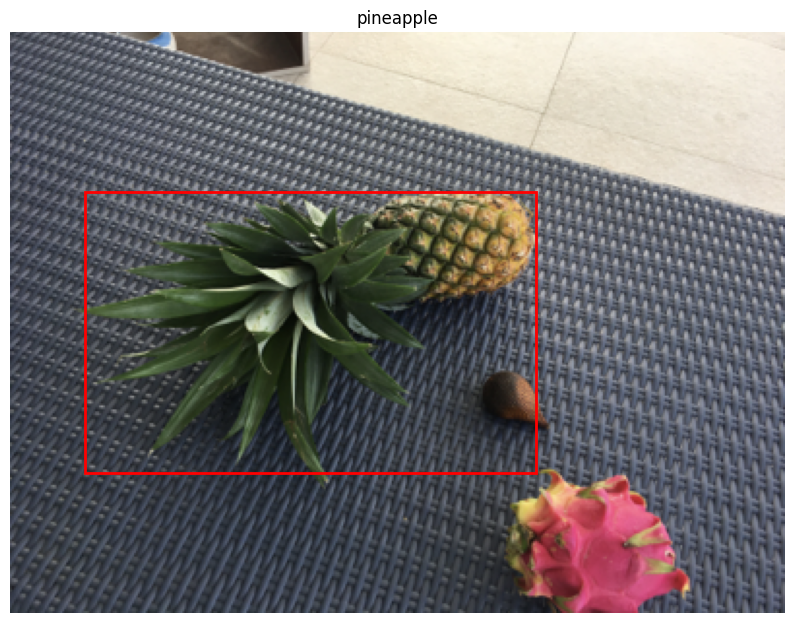

In [ ]:
fig , ax=plt.subplots(figsize=(10,10))
ax.imshow(image)
rect=patches.Rectangle((xmin,ymin),xmax-xmin,ymax-ymin,linewidth=2,edgecolor='r',fill=False)
ax.add_patch(rect)
ax.set_title(label)
ax.axis('off')
plt.show()

In [ ]:
from torchvision import tv_tensors

In [ ]:
bbox=tv_tensors.BoundingBoxes(
    [[xmin,ymin,xmax,ymax]],
    format='XYXY',
    canvas_size=(image.height,image.width)
)

In [ ]:
bbox

BoundingBoxes([[ 38,  82, 271, 227]], format=BoundingBoxFormat.XYXY, canvas_size=(300, 400), clamping_mode=soft)

In [ ]:
transform=v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32,scale=True),
    v2.Resize((224,224))
])
image_transform,bbox_transform=transform(image,bbox)

In [ ]:
bbox_transform[0].tolist()

[21, 61, 151, 169]

In [ ]:
image_transform

Image([[[0.2633, 0.2723, 0.3447,  ..., 0.9534, 0.9681, 0.9692],
        [0.2450, 0.2762, 0.2536,  ..., 0.9490, 0.9528, 0.9555],
        [0.3088, 0.3230, 0.2789,  ..., 0.9494, 0.9442, 0.9347],
        ...,
        [0.2058, 0.2064, 0.2151,  ..., 0.3011, 0.2836, 0.2709],
        [0.1919, 0.2217, 0.2071,  ..., 0.2563, 0.2124, 0.2455],
        [0.1846, 0.2259, 0.1914,  ..., 0.3082, 0.1973, 0.2416]],

       [[0.2826, 0.2949, 0.3620,  ..., 0.9208, 0.9346, 0.9384],
        [0.2647, 0.2971, 0.2669,  ..., 0.9146, 0.9167, 0.9240],
        [0.3229, 0.3364, 0.2921,  ..., 0.9150, 0.9062, 0.8980],
        ...,
        [0.2299, 0.2299, 0.2368,  ..., 0.3195, 0.3001, 0.2856],
        [0.2175, 0.2462, 0.2327,  ..., 0.2719, 0.2231, 0.2635],
        [0.2100, 0.2494, 0.2156,  ..., 0.3265, 0.2063, 0.2595]],

       [[0.3156, 0.3286, 0.4059,  ..., 0.8728, 0.8854, 0.8881],
        [0.3013, 0.3397, 0.3081,  ..., 0.8706, 0.8732, 0.8781],
        [0.3604, 0.3784, 0.3325,  ..., 0.8699, 0.8613, 0.8544],
        ..

In [ ]:
image_show=image_transform.permute(1,2,0).numpy()
image_show

array([[[0.2633113 , 0.282597  , 0.3155603 ],
        [0.2723313 , 0.29487517, 0.32861587],
        [0.34469995, 0.3620276 , 0.40588212],
        ...,
        [0.95339036, 0.920754  , 0.8728231 ],
        [0.968139  , 0.93461484, 0.8854246 ],
        [0.9692194 , 0.9383719 , 0.8880555 ]],

       [[0.24499916, 0.26466686, 0.3012984 ],
        [0.27617037, 0.29711205, 0.3397182 ],
        [0.2536457 , 0.26686966, 0.308141  ],
        ...,
        [0.94897586, 0.9146195 , 0.8706071 ],
        [0.9528069 , 0.9166936 , 0.8731985 ],
        [0.9555289 , 0.924035  , 0.8781012 ]],

       [[0.30880144, 0.32291695, 0.36042076],
        [0.32301176, 0.3363899 , 0.37840915],
        [0.27886537, 0.29209647, 0.33245853],
        ...,
        [0.9494155 , 0.914996  , 0.86985856],
        [0.9442494 , 0.9061776 , 0.86133456],
        [0.9347114 , 0.89798176, 0.8544318 ]],

       ...,

       [[0.2058246 , 0.22990742, 0.26621225],
        [0.20639959, 0.22985373, 0.26460817],
        [0.21514219, 0

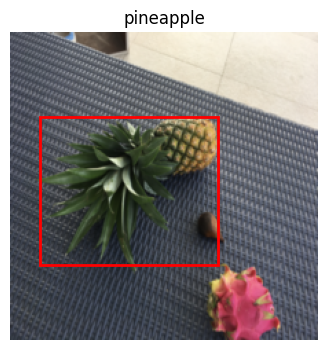

In [ ]:
xmin_t,ymin_t,xmax_t,ymax_t=bbox_transform[0].tolist()
fig , ax=plt.subplots(figsize=(6,4))
ax.imshow(image_show)
rect=patches.Rectangle((xmin_t,ymin_t),xmax_t-xmin_t,ymax_t-ymin_t,linewidth=2,edgecolor='r',fill=False)
ax.add_patch(rect)
ax.set_title(label)
ax.axis('off')
plt.show()

In [ ]:
! curl -L -o 26-class-object-detection-dataset.zip\
  https://www.kaggle.com/api/v1/datasets/download/mohamedgobara/26-class-object-detection-dataset

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 1031M  100 1031M    0     0  95.7M      0  0:00:10  0:00:10 --:--:-- 92.6M


In [ ]:
!unzip -q /content/26-class-object-detection-dataset.zip -d urban_detection

In [ ]:
from pathlib import Path
import os

DATA_ROOT=Path('/content/urban_detection/Senior-Design-VIAD-4')

In [ ]:
import json

train_json_path=DATA_ROOT / 'train' / '_annotations.coco.json'

with open(train_json_path,'r') as f:
  coco=json.load(f)

print(coco.keys())

dict_keys(['info', 'licenses', 'categories', 'images', 'annotations'])


In [ ]:
coco['categories']

[{'id': 0, 'name': 'cars-bikes-people', 'supercategory': 'none'},
 {'id': 1, 'name': 'Bus', 'supercategory': 'cars-bikes-people'},
 {'id': 2, 'name': 'Bushes', 'supercategory': 'cars-bikes-people'},
 {'id': 3, 'name': 'Person', 'supercategory': 'cars-bikes-people'},
 {'id': 4, 'name': 'Truck', 'supercategory': 'cars-bikes-people'},
 {'id': 5, 'name': 'backpack', 'supercategory': 'cars-bikes-people'},
 {'id': 6, 'name': 'bench', 'supercategory': 'cars-bikes-people'},
 {'id': 7, 'name': 'bicycle', 'supercategory': 'cars-bikes-people'},
 {'id': 8, 'name': 'boat', 'supercategory': 'cars-bikes-people'},
 {'id': 9, 'name': 'branch', 'supercategory': 'cars-bikes-people'},
 {'id': 10, 'name': 'car', 'supercategory': 'cars-bikes-people'},
 {'id': 11, 'name': 'chair', 'supercategory': 'cars-bikes-people'},
 {'id': 12, 'name': 'clock', 'supercategory': 'cars-bikes-people'},
 {'id': 13, 'name': 'crosswalk', 'supercategory': 'cars-bikes-people'},
 {'id': 14, 'name': 'door', 'supercategory': 'cars-b

In [ ]:
coco['info']

{'year': '2024',
 'version': '4',
 'description': 'Exported from roboflow.com',
 'contributor': '',
 'url': 'https://public.roboflow.com/object-detection/undefined',
 'date_created': '2024-02-06T15:35:56+00:00'}

In [ ]:
coco['images'][:5]

[{'id': 0,
  'license': 1,
  'file_name': '15103310083_e6cb39844c_o_jpg.rf.fb4b2ea34fd7128dc8390fab5df0fa71.jpg',
  'height': 300,
  'width': 300,
  'date_captured': '2024-02-06T15:35:56+00:00'},
 {'id': 1,
  'license': 1,
  'file_name': 'a2_015_jpg.rf.fb6004be06889cefb1b1794baaadb3f0.jpg',
  'height': 300,
  'width': 300,
  'date_captured': '2024-02-06T15:35:56+00:00'},
 {'id': 2,
  'license': 1,
  'file_name': '25_jpg.rf.fb5e27f40a2f81495ca18465ed081d3f.jpg',
  'height': 300,
  'width': 300,
  'date_captured': '2024-02-06T15:35:56+00:00'},
 {'id': 3,
  'license': 1,
  'file_name': 'traffic-light-172-_jpg.rf.fb3e86fd579e8b4c5c704f981b9d0193.jpg',
  'height': 300,
  'width': 300,
  'date_captured': '2024-02-06T15:35:56+00:00'},
 {'id': 4,
  'license': 1,
  'file_name': 'z4640749814487_8f1346fd060119438434bf6838452337_jpg.rf.fb3fc09246bf7163ea34dceb4bfb0fce.jpg',
  'height': 300,
  'width': 300,
  'date_captured': '2024-02-06T15:35:56+00:00'}]

In [ ]:
coco['annotations'][:10]

[{'id': 0,
  'image_id': 0,
  'category_id': 23,
  'bbox': [91, 76, 120.5, 115.5],
  'area': 13917.75,
  'segmentation': [],
  'iscrowd': 0},
 {'id': 1,
  'image_id': 2,
  'category_id': 1,
  'bbox': [16, 81, 266.5, 178.5],
  'area': 47570.25,
  'segmentation': [],
  'iscrowd': 0},
 {'id': 2,
  'image_id': 3,
  'category_id': 24,
  'bbox': [35, 200, 19.5, 50.5],
  'area': 984.75,
  'segmentation': [],
  'iscrowd': 0},
 {'id': 3,
  'image_id': 3,
  'category_id': 24,
  'bbox': [264, 67, 23, 52.5],
  'area': 1207.5,
  'segmentation': [],
  'iscrowd': 0},
 {'id': 4,
  'image_id': 4,
  'category_id': 1,
  'bbox': [44, 20, 146.256, 273.401],
  'area': 39986.487,
  'segmentation': [[179.407,
    23.791,
    151.326,
    19.891,
    124.415,
    21.841,
    44.462,
    268.721,
    190.718,
    293.292,
    179.407,
    23.791]],
  'iscrowd': 0},
 {'id': 5,
  'image_id': 4,
  'category_id': 10,
  'bbox': [248, 72, 51, 79],
  'area': 4029,
  'segmentation': [],
  'iscrowd': 0},
 {'id': 6,
  'i

In [ ]:
cat_id_to_name={}

for cat in coco['categories']:
  cat_id_to_name[cat['id']]=cat['name']

cat_id_to_name

{0: 'cars-bikes-people',
 1: 'Bus',
 2: 'Bushes',
 3: 'Person',
 4: 'Truck',
 5: 'backpack',
 6: 'bench',
 7: 'bicycle',
 8: 'boat',
 9: 'branch',
 10: 'car',
 11: 'chair',
 12: 'clock',
 13: 'crosswalk',
 14: 'door',
 15: 'elevator',
 16: 'fire_hydrant',
 17: 'green_light',
 18: 'gun',
 19: 'handbag',
 20: 'motorcycle',
 21: 'person',
 22: 'pothole',
 23: 'rat',
 24: 'red_light',
 25: 'scooter',
 26: 'sheep',
 27: 'stairs',
 28: 'stop_sign',
 29: 'suitcase',
 30: 'traffic light',
 31: 'traffic_cone',
 32: 'train',
 33: 'tree',
 34: 'truck',
 35: 'umbrella',
 36: 'yellow_light'}

In [ ]:
from collections import defaultdict

image_id_to_annotations=defaultdict(list)

for ann in coco['annotations']:
  image_id_to_annotations[ann['image_id']].append(ann)

In [ ]:
cat_id_to_name[23]

'rat'

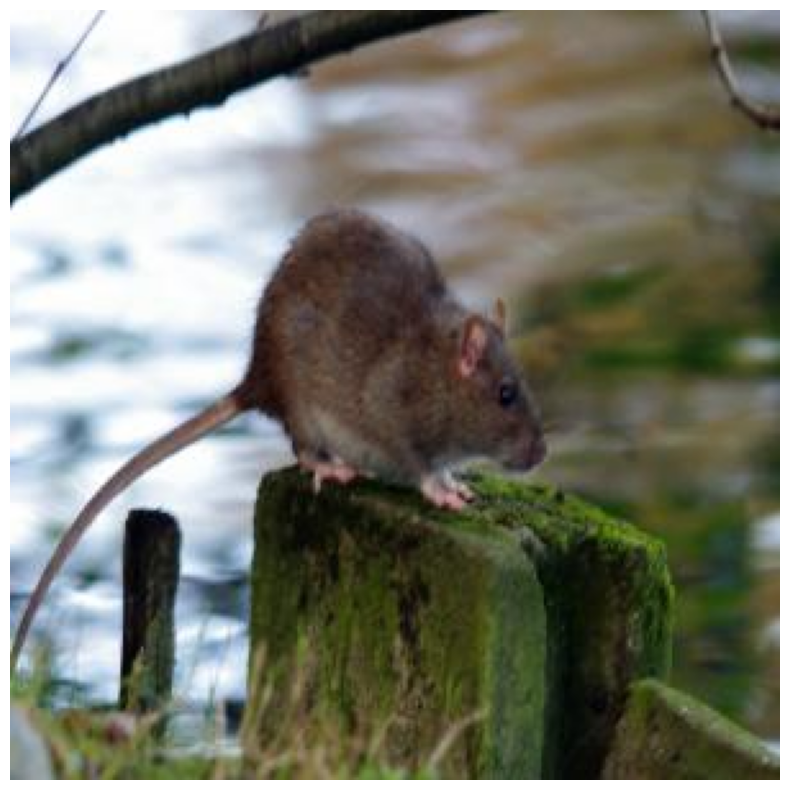

In [ ]:
img_info=coco['images'][0]
file_name=img_info['file_name']

img_path=DATA_ROOT / 'train' / file_name

image=Image.open(img_path).convert("RGB")

plt.figure(figsize=(10,10))
plt.imshow(image)
plt.axis('off')
plt.show()

In [ ]:
img_id=img_info['id']
anns=image_id_to_annotations[img_id]
boxes=[]
labels=[]
for ann in anns:
  x,y,w,h=ann['bbox']
  category_id=ann['category_id']
  boxes.append([x,y,w,h])
  labels.append(category_id)
boxes=tv_tensors.BoundingBoxes(
    boxes,
    format='XYWH',
    canvas_size=(image.height,image.width)
)

labels=torch.tensor(labels,dtype=torch.long)

print(boxes)
print(labels)

BoundingBoxes([[ 91.0000,  76.0000, 120.5000, 115.5000]], format=BoundingBoxFormat.XYWH, canvas_size=(300, 300), clamping_mode=soft)
tensor([23])


In [ ]:
transform=v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32,scale=True),
    v2.Resize((224,224))
])
image_t,bbox_t=transform(image,boxes)

In [ ]:
MAX_OBJECT=10
IMAGE_SIZE=224

In [ ]:
from torchvision.ops import box_convert

In [ ]:
class COCOSimpleDetectionDataset(Dataset):
    def __init__(self, split_dir, max_objects=10, transforms=None):
        self.split_dir = Path(split_dir)
        self.annotation_path = self.split_dir / "_annotations.coco.json"
        self.max_objects = max_objects
        self.transforms = transforms

        with open(self.annotation_path, "r") as f:
            self.coco = json.load(f)

        self.images = self.coco["images"]
        self.annotations = self.coco["annotations"]
        self.categories = self.coco["categories"]

        self.cat_id_to_name = {
            cat["id"]: cat["name"]
            for cat in self.categories
        }

        self.cat_id_to_idx = {
            cat["id"]: idx
            for idx, cat in enumerate(self.categories)
        }

        self.idx_to_name = {
            idx: cat["name"]
            for idx, cat in enumerate(self.categories)
        }

        self.image_id_to_annotations = defaultdict(list)

        for ann in self.annotations:
            self.image_id_to_annotations[ann["image_id"]].append(ann)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_info = self.images[idx]

        image_id = img_info["id"]
        file_name = img_info["file_name"]
        img_path = self.split_dir / file_name

        image = Image.open(img_path).convert("RGB")

        anns = self.image_id_to_annotations[image_id]

        boxes_xywh = []
        labels = []

        for ann in anns:
            x, y, w, h = ann["bbox"]

            if w <= 0 or h <= 0:
                continue

            boxes_xywh.append([x, y, w, h])

            category_id = ann["category_id"]
            label_idx = self.cat_id_to_idx[category_id]
            labels.append(label_idx)

        if len(boxes_xywh) == 0:
            boxes_xywh = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.long)
        else:
            boxes_xywh = tv_tensors.BoundingBoxes(
                boxes_xywh,
                format="XYWH",
                canvas_size=(image.height, image.width)
            )
            labels = torch.tensor(labels, dtype=torch.long)

        if self.transforms is not None:
            image, boxes_xywh = self.transforms(image, boxes_xywh)

        if len(boxes_xywh) > 0:
            boxes_cxcywh = box_convert(
                torch.as_tensor(boxes_xywh, dtype=torch.float32),
                in_fmt="xywh",
                out_fmt="cxcywh"
            )

            _, h, w = image.shape

            boxes_cxcywh = boxes_cxcywh / torch.tensor(
                [w, h, w, h],
                dtype=torch.float32
            )


            sort_idx = torch.argsort(boxes_cxcywh[:, 0])
            boxes_cxcywh = boxes_cxcywh[sort_idx]
            labels = labels[sort_idx]

            boxes_cxcywh = boxes_cxcywh[:self.max_objects]
            labels = labels[:self.max_objects]

        objectness = torch.zeros(self.max_objects, dtype=torch.float32)
        target_labels = torch.full((self.max_objects,), -100, dtype=torch.long)
        target_boxes = torch.zeros((self.max_objects, 4), dtype=torch.float32)

        num_objects = min(len(labels), self.max_objects)

        if num_objects > 0:
            objectness[:num_objects] = 1.0
            target_labels[:num_objects] = labels[:num_objects]
            target_boxes[:num_objects] = boxes_cxcywh[:num_objects]

        target = {
            "objectness": objectness,
            "labels": target_labels,
            "boxes": target_boxes,
            "image_id": torch.tensor(image_id),
            "image_path": str(img_path)
        }

        return image, target

In [ ]:
train_dataset=COCOSimpleDetectionDataset(
    DATA_ROOT / 'train',
    MAX_OBJECT,
    transform
)

In [ ]:
image,target=train_dataset[0]

print('Image shape',image.shape)
print('Objectness',target['objectness'])
print('Labels',target['labels'])
print('Boxes',target['boxes'])
print('Image ID',target['image_id'])
print('Image Path',target['image_path'])

Image shape torch.Size([3, 224, 224])
Objectness tensor([1., 0., 0., 0., 0., 0., 0., 0., 0., 0.])
Labels tensor([  23, -100, -100, -100, -100, -100, -100, -100, -100, -100])
Boxes tensor([[0.5042, 0.4458, 0.4017, 0.3850],
        [0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000]])
Image ID tensor(0)
Image Path /content/urban_detection/Senior-Design-VIAD-4/train/15103310083_e6cb39844c_o_jpg.rf.fb4b2ea34fd7128dc8390fab5df0fa71.jpg


In [ ]:
valid_dataset=COCOSimpleDetectionDataset(
    DATA_ROOT / 'valid',
    MAX_OBJECT,
    transform
)
test_dataset=COCOSimpleDetectionDataset(
    DATA_ROOT / 'test',
    MAX_OBJECT,
    transform
)
print('Train',len(train_dataset))
print('Valid',len(valid_dataset))
print('Test',len(test_dataset))

Train 32511
Valid 4246
Test 2165


In [ ]:
def collete_fn(batch):
  images=[]
  targets={
          'objectness':[],
          'labels':[],
          'boxes':[],
          'image_id':[],
          'image_path':[]
  }
  for image,target in batch:
    images.append(image)
    targets['objectness'].append(target['objectness'])
    targets['labels'].append(target['labels'])
    targets['boxes'].append(target['boxes'])
    targets['image_id'].append(target['image_id'])
    targets['image_path'].append(target['image_path'])

  images=torch.stack(images)
  targets['objectness']=torch.stack(targets['objectness'])
  targets['labels']=torch.stack(targets['labels'])
  targets['boxes']=torch.stack(targets['boxes'])
  targets['image_id']=torch.stack(targets['image_id'])
  return images,targets

In [ ]:
BATCH_SIZE=16

train_loader=DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collete_fn,
)

valid_loader=DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collete_fn,
)
test_loader=DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collete_fn,
)

In [ ]:
train_loader

In [ ]:
images,targets=next(iter(train_loader))
print('Images shape',images.shape)
print('Objectness',targets['objectness'].shape)
print('Labels',targets['labels'].shape)
print('Boxes',targets['boxes'].shape)
print('Image ID',targets['image_id'].shape)
print('Image Path',targets['image_path'][0])

Images shape torch.Size([16, 3, 224, 224])
Objectness torch.Size([16, 10])
Labels torch.Size([16, 10])
Boxes torch.Size([16, 10, 4])
Image ID torch.Size([16])
Image Path /content/urban_detection/Senior-Design-VIAD-4/train/4_z8126b7d060d92d74599e0618_f109f07e1c331f50e_d20161224_m030423_c001_v0001037_t0042_png.rf.9974418b2129e6a2b74a3426ae182daf.jpg


In [ ]:
import torch.nn as nn
from torchvision.models import resnet18,ResNet18_Weights

In [ ]:
class COCOSimpleDetectionDataset(Dataset):
    def __init__(self, split_dir, max_objects=10, transforms=None):
        self.split_dir = Path(split_dir)
        self.annotation_path = self.split_dir / "_annotations.coco.json"
        self.max_objects = max_objects
        self.transforms = transforms

        with open(self.annotation_path, "r") as f:
            self.coco = json.load(f)

        self.images = self.coco["images"]
        self.annotations = self.coco["annotations"]
        self.categories = self.coco["categories"]

        self.cat_id_to_name = {
            cat["id"]: cat["name"]
            for cat in self.categories
        }

        self.cat_id_to_idx = {
            cat["id"]: idx
            for idx, cat in enumerate(self.categories)
        }

        self.idx_to_name = {
            idx: cat["name"]
            for idx, cat in enumerate(self.categories)
        }

        self.image_id_to_annotations = defaultdict(list)

        for ann in self.annotations:
            self.image_id_to_annotations[ann["image_id"]].append(ann)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_info = self.images[idx]

        image_id = img_info["id"]
        file_name = img_info["file_name"]
        img_path = self.split_dir / file_name

        image = Image.open(img_path).convert("RGB")

        anns = self.image_id_to_annotations[image_id]

        boxes_xywh = []
        labels = []

        for ann in anns:
            x, y, w, h = ann["bbox"]

            if w <= 0 or h <= 0:
                continue

            boxes_xywh.append([x, y, w, h])

            category_id = ann["category_id"]
            label_idx = self.cat_id_to_idx[category_id]
            labels.append(label_idx)

        if len(boxes_xywh) == 0:
            boxes_xywh = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.long)
        else:
            boxes_xywh = tv_tensors.BoundingBoxes(
                boxes_xywh,
                format="XYWH",
                canvas_size=(image.height, image.width)
            )
            labels = torch.tensor(labels, dtype=torch.long)

        if self.transforms is not None:
            image, boxes_xywh = self.transforms(image, boxes_xywh)

        if len(boxes_xywh) > 0:
            boxes_cxcywh = box_convert(
                torch.as_tensor(boxes_xywh, dtype=torch.float32),
                in_fmt="xywh",
                out_fmt="cxcywh"
            )

            _, h, w = image.shape

            boxes_cxcywh = boxes_cxcywh / torch.tensor(
                [w, h, w, h],
                dtype=torch.float32
            )


            sort_idx = torch.argsort(boxes_cxcywh[:, 0])
            boxes_cxcywh = boxes_cxcywh[sort_idx]
            labels = labels[sort_idx]

            boxes_cxcywh = boxes_cxcywh[:self.max_objects]
            labels = labels[:self.max_objects]

        objectness = torch.zeros(self.max_objects, dtype=torch.float32)
        target_labels = torch.full((self.max_objects,), -100, dtype=torch.long)
        target_boxes = torch.zeros((self.max_objects, 4), dtype=torch.float32)

        num_objects = min(len(labels), self.max_objects)

        if num_objects > 0:
            objectness[:num_objects] = 1.0
            target_labels[:num_objects] = labels[:num_objects]
            target_boxes[:num_objects] = boxes_cxcywh[:num_objects]

        target = {
            "objectness": objectness,
            "labels": target_labels,
            "boxes": target_boxes,
            "image_id": torch.tensor(image_id),
            "image_path": str(img_path)
        }

        return image, target

In [ ]:
class SimpleResNetDetector(nn.Module):
    def __init__(self, num_classes, max_objects=10):
        super().__init__()

        self.num_classes = num_classes
        self.max_objects = max_objects

        weights = ResNet18_Weights.DEFAULT
        backbone = resnet18(weights=weights)

        in_features = backbone.fc.in_features
        backbone.fc = nn.Identity()

        self.backbone = backbone

        self.objectness_head = nn.Linear(in_features, max_objects)

        self.class_head = nn.Linear(
            in_features,
            max_objects * num_classes
        )

        self.bbox_head = nn.Sequential(
            nn.Linear(in_features, max_objects * 4),
            nn.Sigmoid()
        )

    def forward(self, x):
        features = self.backbone(x)

        objectness_logits = self.objectness_head(features)

        class_logits = self.class_head(features)
        class_logits = class_logits.view(
            -1,
            self.max_objects,
            self.num_classes
        )

        boxes = self.bbox_head(features)
        boxes = boxes.view(
            -1,
            self.max_objects,
            4
        )

        return objectness_logits, class_logits, boxes

In [ ]:
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [ ]:
device

device(type='cuda')

In [ ]:
num_classes=len(train_dataset.categories)
model=SimpleResNetDetector(num_classes,MAX_OBJECT).to(device)
images=images.to(device)
objectness_logits,class_logits,box_preds=model(images)
print(objectness_logits.shape)
print(class_logits.shape)
print(box_preds.shape)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 150MB/s]


torch.Size([16, 10])
torch.Size([16, 10, 37])
torch.Size([16, 10, 4])


In [ ]:
objectness_loss_fn=nn.BCEWithLogitsLoss()
classification_loss_fn=nn.CrossEntropyLoss(ignore_index=-100)
bbox_loss_fn=nn.SmoothL1Loss()

In [ ]:
def compute_loss(objectness_logits, class_logits, box_preds, targets):
    objectness_targets = targets["objectness"].to(device)
    label_targets = targets["labels"].to(device)
    box_targets = targets["boxes"].to(device)

    obj_loss = objectness_loss_fn(
        objectness_logits,
        objectness_targets
    )

    cls_loss = classification_loss_fn(
        class_logits.reshape(-1, class_logits.shape[-1]),
        label_targets.reshape(-1)
    )

    positive_mask = objectness_targets == 1

    if positive_mask.sum() > 0:
        bbox_loss = bbox_loss_fn(
            box_preds[positive_mask],
            box_targets[positive_mask]
        )
    else:
        bbox_loss = torch.tensor(0.0, device=device)

    total_loss = obj_loss + cls_loss + bbox_loss

    return total_loss, obj_loss, cls_loss, bbox_loss

In [ ]:
optimizer=torch.optim.Adam(model.parameters(),lr=1e-4)
num_epochs=5

In [ ]:
for epoch in range(num_epochs):
    model.train()

    train_loss = 0.0
    train_obj_loss = 0.0
    train_cls_loss = 0.0
    train_bbox_loss = 0.0

    for images, targets in tqdm(train_loader):
        images = images.to(device)

        objectness_logits, class_logits, box_preds = model(images)

        loss, obj_loss, cls_loss, bbox_loss = compute_loss(
            objectness_logits,
            class_logits,
            box_preds,
            targets
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_obj_loss += obj_loss.item()
        train_cls_loss += cls_loss.item()
        train_bbox_loss += bbox_loss.item()

    train_loss /= len(train_loader)
    train_obj_loss /= len(train_loader)
    train_cls_loss /= len(train_loader)
    train_bbox_loss /= len(train_loader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Obj: {train_obj_loss:.4f} "
        f"Cls: {train_cls_loss:.4f} "
        f"BBox: {train_bbox_loss:.4f}"
    )

  0%|          | 0/2032 [00:00<?, ?it/s]

Epoch [1/5] Train Loss: 0.8856 Obj: 0.1501 Cls: 0.7174 BBox: 0.0181


  0%|          | 0/2032 [00:00<?, ?it/s]

Epoch [2/5] Train Loss: 0.3200 Obj: 0.0897 Cls: 0.2161 BBox: 0.0142


  0%|          | 0/2032 [00:00<?, ?it/s]

Epoch [3/5] Train Loss: 0.1977 Obj: 0.0637 Cls: 0.1213 BBox: 0.0127


  0%|          | 0/2032 [00:00<?, ?it/s]

Epoch [4/5] Train Loss: 0.1303 Obj: 0.0482 Cls: 0.0704 BBox: 0.0116


  0%|          | 0/2032 [00:00<?, ?it/s]

Epoch [5/5] Train Loss: 0.0938 Obj: 0.0382 Cls: 0.0449 BBox: 0.0107


Sample 1/10 | Image index: 912


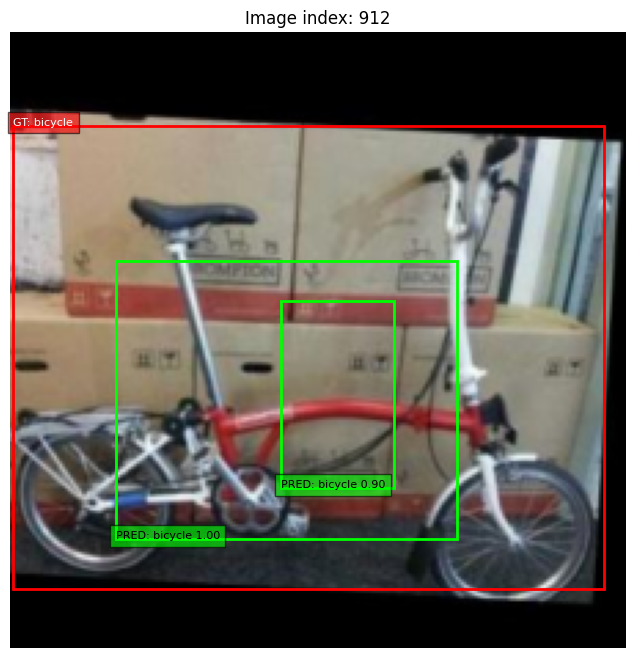

Sample 2/10 | Image index: 204


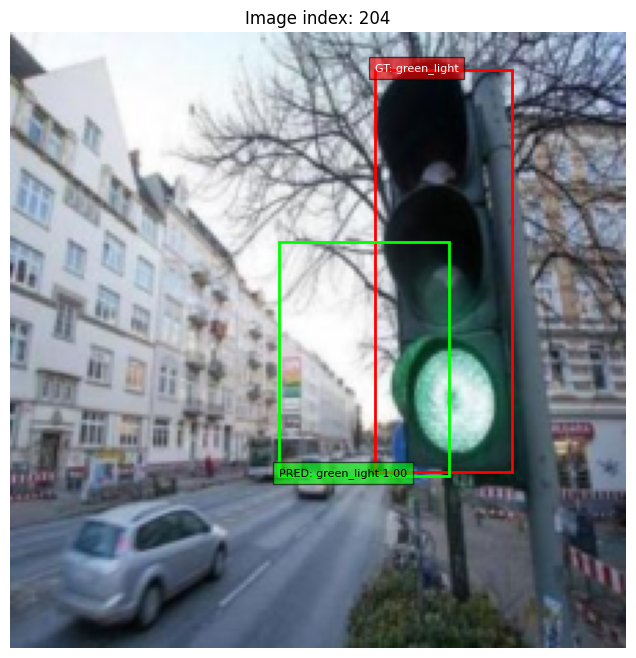

Sample 3/10 | Image index: 2253


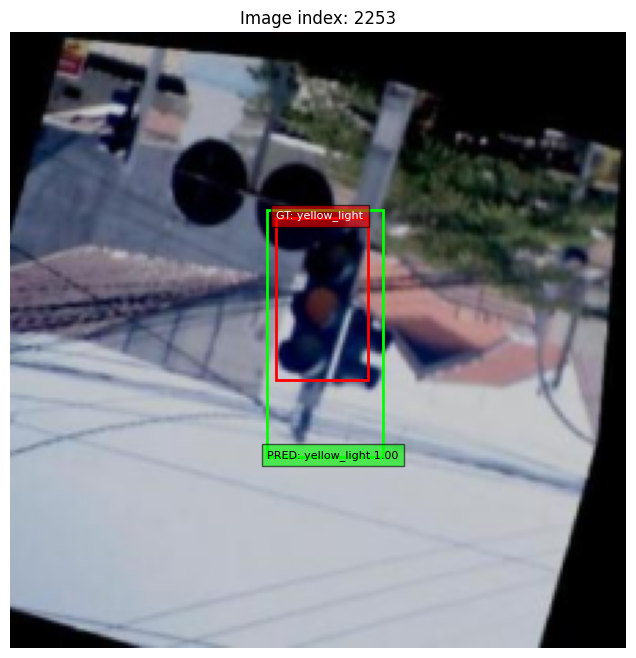

Sample 4/10 | Image index: 2006


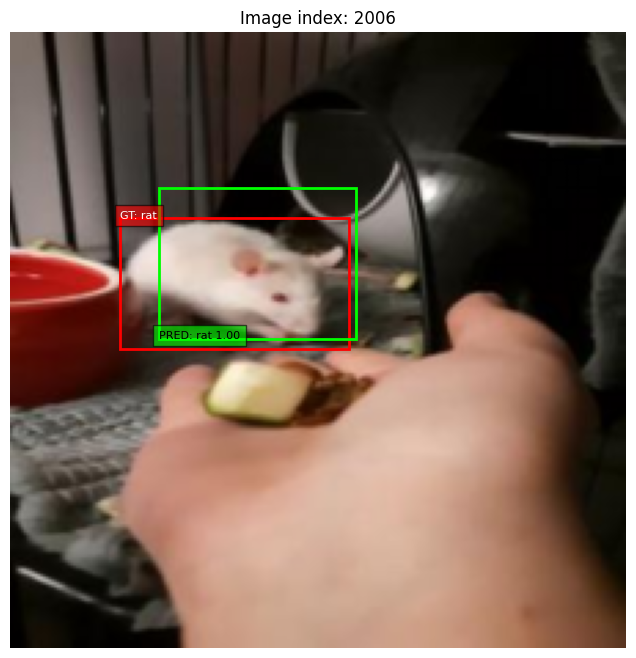

Sample 5/10 | Image index: 1828


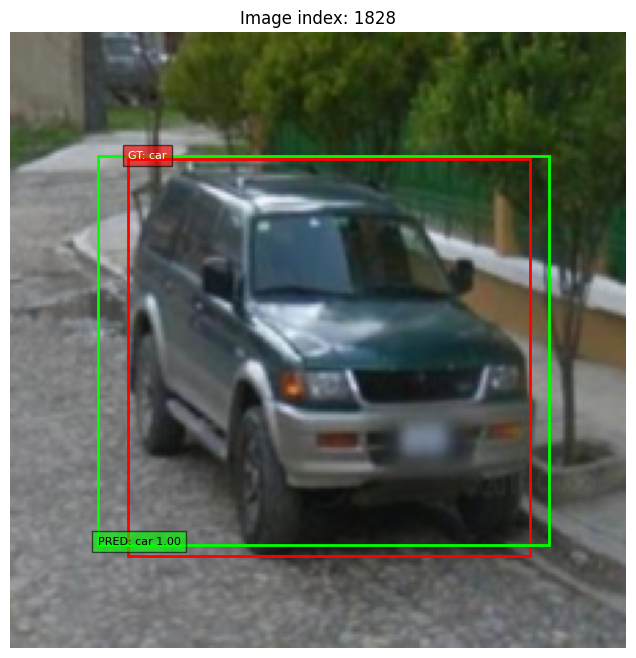

Sample 6/10 | Image index: 1143


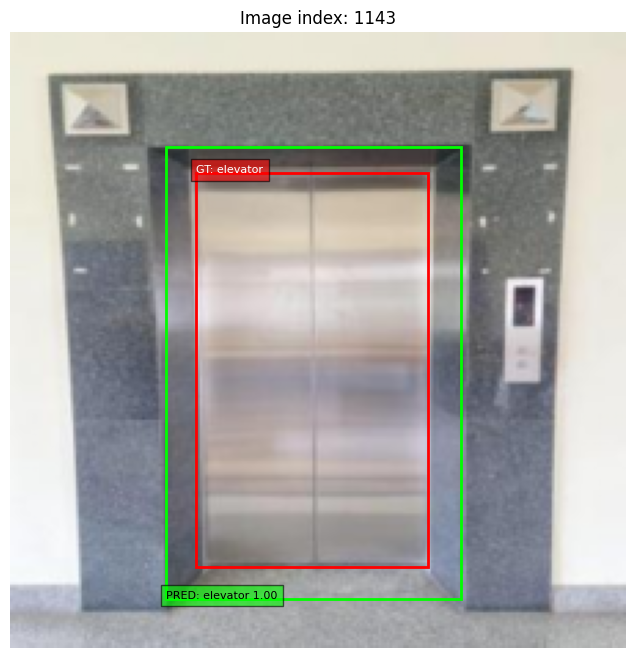

Sample 7/10 | Image index: 839


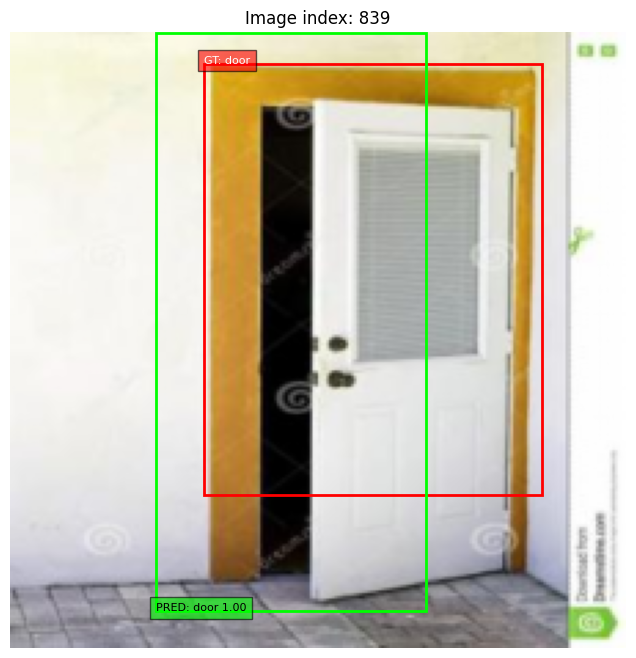

Sample 8/10 | Image index: 712


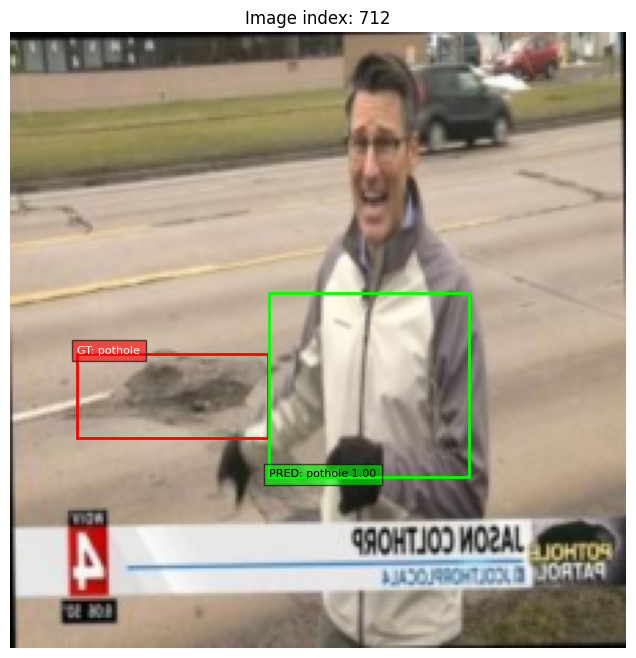

Sample 9/10 | Image index: 3456


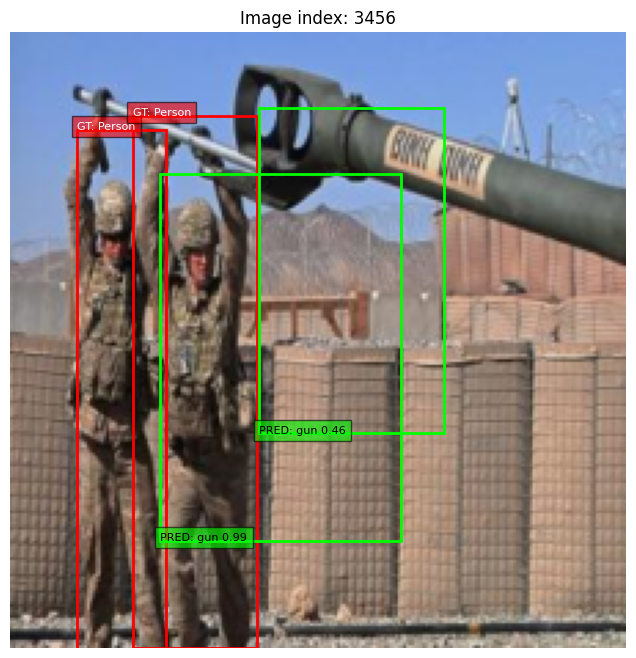

Sample 10/10 | Image index: 260


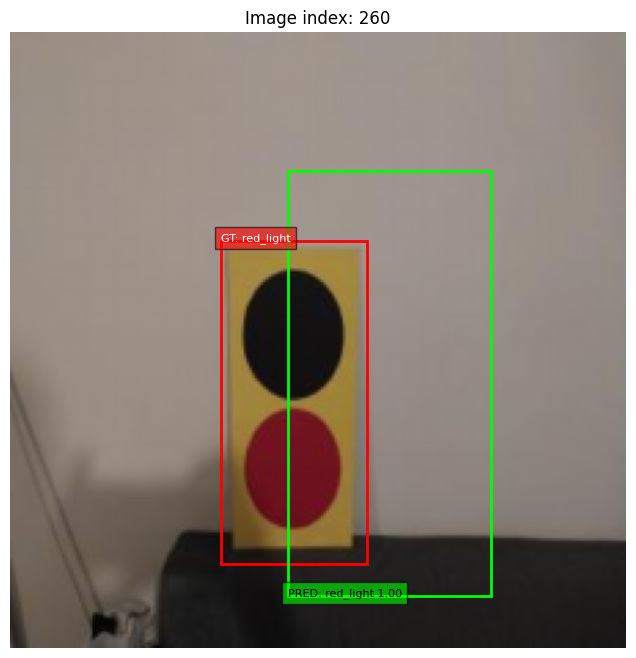

In [ ]:
import random
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches


def cxcywh_to_xyxy_single(box):
    cx, cy, w, h = box

    x1 = cx - w / 2
    y1 = cy - h / 2
    x2 = cx + w / 2
    y2 = cy + h / 2

    return x1, y1, x2, y2


def visualize_gt_and_predictions(model, dataset, idx=0, score_threshold=0.4):
    model.eval()

    image, target = dataset[idx]

    with torch.no_grad():
        input_image = image.unsqueeze(0).to(device)

        objectness_logits, class_logits, box_preds = model(input_image)

        objectness_probs = torch.sigmoid(objectness_logits)[0].cpu()
        class_probs = torch.softmax(class_logits[0].cpu(), dim=-1)
        pred_labels = torch.argmax(class_probs, dim=-1)
        pred_boxes = box_preds[0].cpu()

    image_np = image.permute(1, 2, 0).numpy()
    H, W = image.shape[1], image.shape[2]

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(image_np)


    for i in range(MAX_OBJECT):
        if target["objectness"][i] == 0:
            continue

        box = target["boxes"][i]
        x1, y1, x2, y2 = cxcywh_to_xyxy_single(box)

        x1 = x1.item() * W
        y1 = y1.item() * H
        x2 = x2.item() * W
        y2 = y2.item() * H

        label_idx = target["labels"][i].item()
        class_name = dataset.idx_to_name[label_idx]

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor="red",
            fill=False
        )
        ax.add_patch(rect)

        ax.text(
            x1,
            y1,
            f"GT: {class_name}",
            fontsize=8,
            color="white",
            bbox=dict(facecolor="red", alpha=0.6)
        )


    for i in range(MAX_OBJECT):
        score = objectness_probs[i].item()

        if score < score_threshold:
            continue

        box = pred_boxes[i]
        x1, y1, x2, y2 = cxcywh_to_xyxy_single(box)

        x1 = x1.item() * W
        y1 = y1.item() * H
        x2 = x2.item() * W
        y2 = y2.item() * H

        label_idx = pred_labels[i].item()
        class_name = dataset.idx_to_name[label_idx]

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor="lime",
            fill=False
        )
        ax.add_patch(rect)

        ax.text(
            x1,
            y2,
            f"PRED: {class_name} {score:.2f}",
            fontsize=8,
            color="black",
            bbox=dict(facecolor="lime", alpha=0.6)
        )

    ax.set_title(f"Image index: {idx}")
    ax.axis("off")
    plt.show()



random.seed(42)

for n in range(10):
    idx = random.randint(0, len(valid_dataset) - 1)

    print("=" * 60)
    print(f"Sample {n + 1}/10 | Image index: {idx}")

    visualize_gt_and_predictions(
        model=model,
        dataset=valid_dataset,
        idx=idx,
        score_threshold=0.4
    )